In [1]:
import ast
from collections import Counter
import json
import re
import time
import warnings

from bs4 import BeautifulSoup
import folium
from googlesearch import search
from kiwipiepy import Kiwi
from konlpy.tag import Okt
import matplotlib
from matplotlib import font_manager, rc
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBClassifier
from xgboost import XGBRegressor
from lightgbm import LGBMClassifier
from lightgbm import LGBMRegressor
from wordcloud import WordCloud
from sklearn.datasets import fetch_olivetti_faces
from tensorflow.keras.datasets import cifar10
from sklearn.decomposition import PCA
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

plt.rcParams['axes.unicode_minus'] = False

# 경고 메시지 무시 설정
warnings.filterwarnings(action='ignore')

# 매직 명령어 및 소수점 설정
%precision 3
%matplotlib inline

# 한글 폰트 설정 (Windows 맑은 고딕)
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties(fname=font_path).get_name()
matplotlib.rc('font', family=font_name)

c:\Users\smart\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


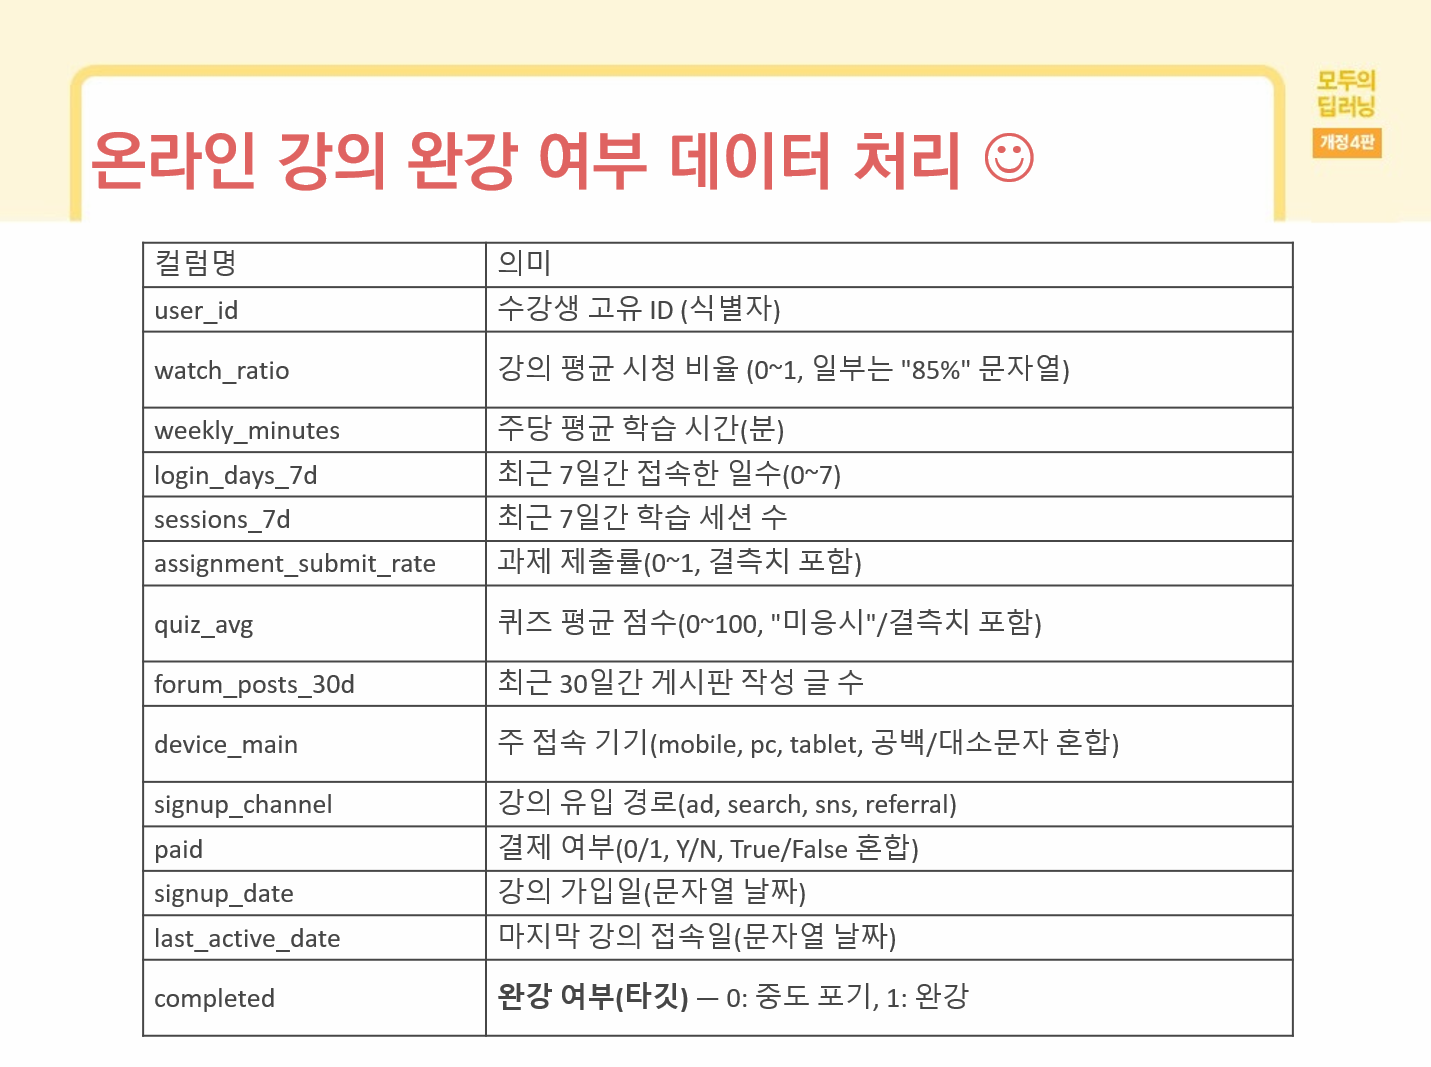

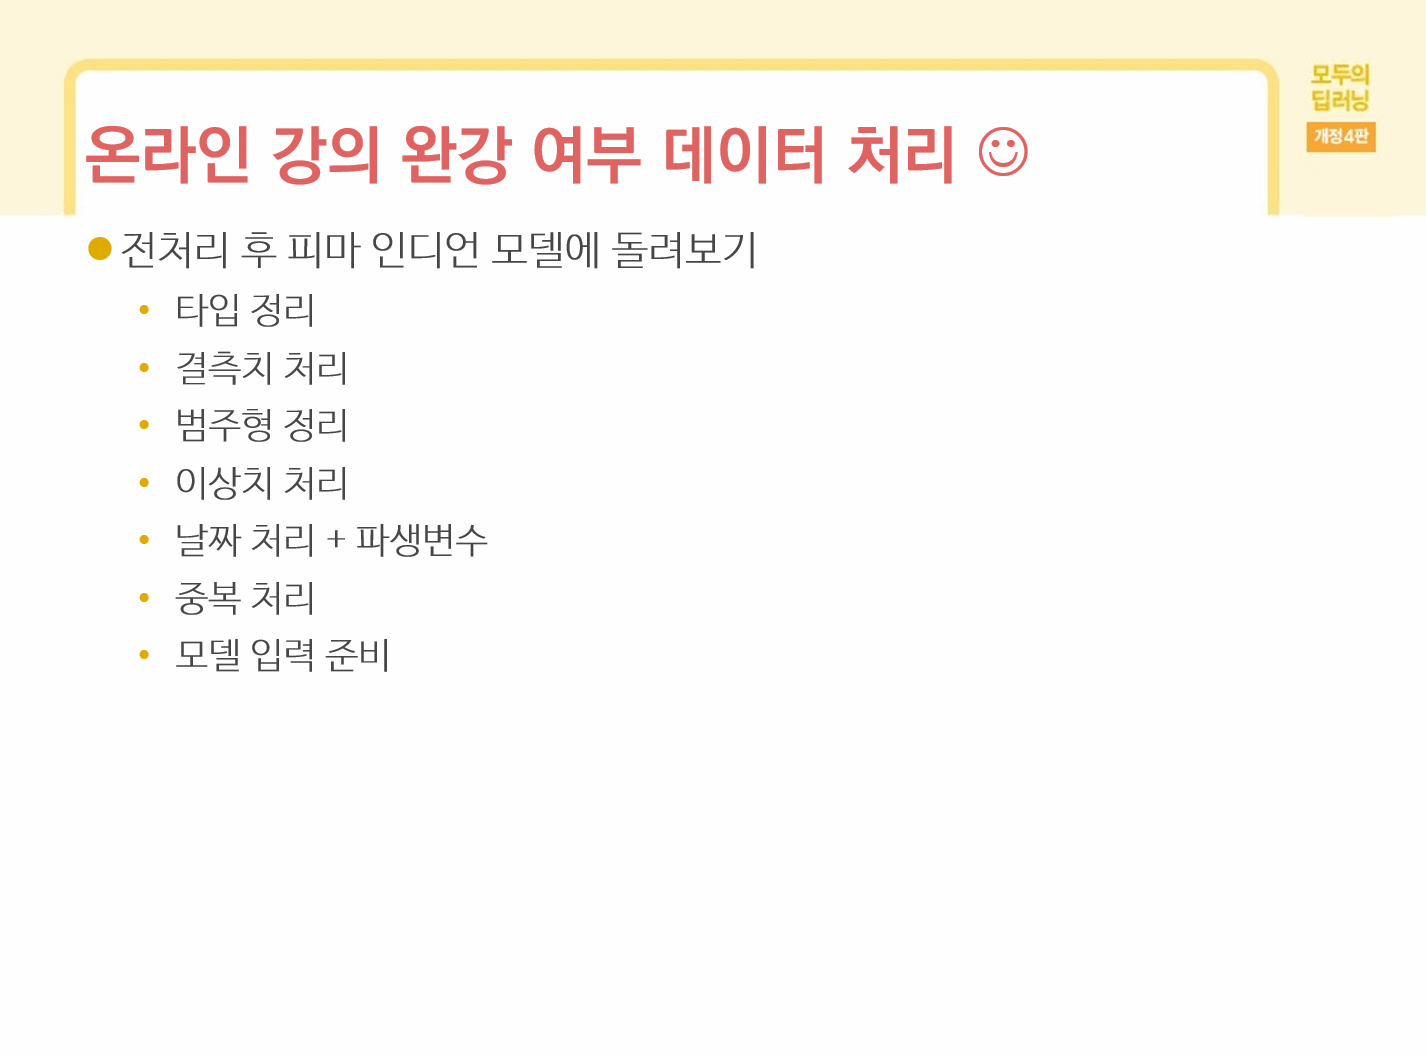

In [2]:
df = pd.read_csv('./course_completion_raw_1000.csv')

In [3]:
df.head()

,user_id,watch_ratio,weekly_minutes,login_days_7d,sessions_7d,assignment_submit_rate,quiz_avg,forum_posts_30d,device_main,signup_channel,paid,signup_date,last_active_date,completed
0,U180325,0.6442216086075401,128.678281,3,7,0.061761,100.0,0,mobile,ad,0,2025-08-26,2025-09-13,0
1,U796559,0.4182103636005199,155.622686,0,16,0.489122,51.141686150605835,0,mobile,sns,1,2025-03-25,2025-09-20,0
2,U689113,0.5728484529558512,48.748187,5,15,0.173168,78.82202453648044,1,pc,sns,True,2025-08-27,2025-10-23,0
3,U494990,0.44506089232258156,230.454431,5,11,0.634181,97.64804599078026,0,pc,search,Y,2025-06-25,2025-12-13,1
4,U489713,0.7892551378540293,146.199604,5,11,0.109690,55.55574005481784,0,mobile,search,0,2025-01-09,2025-02-26,0


In [4]:
df.describe()

,weekly_minutes,login_days_7d,sessions_7d,assignment_submit_rate,forum_posts_30d,completed
count,1000.000000,1000.000000,1000.000000,940.000000,1000.000000,1000.000000
mean,206.752298,3.459000,9.978000,0.454334,1.217000,0.412000
std,553.309162,2.304698,3.187111,0.214819,1.066325,0.492441
min,9.512573,0.000000,1.000000,0.010519,0.000000,0.000000
25%,78.054849,1.000000,8.000000,0.287265,0.000000,0.000000
50%,130.260062,3.000000,10.000000,0.444011,1.000000,0.000000
75%,189.854595,5.000000,12.000000,0.605806,2.000000,1.000000
max,6024.826741,7.000000,21.000000,0.986644,5.000000,1.000000


In [5]:
df['weekly_minutes'][df['weekly_minutes']>=400].count()

np.int64(23)

In [6]:
Q1 = df['weekly_minutes'].quantile(0.25)
Q3 = df['weekly_minutes'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + (1.5 * IQR)

df['weekly_minutes'] = df['weekly_minutes'].clip(upper=upper_bound)

In [7]:
df['weekly_minutes'][df['weekly_minutes']>=400]

Series([], Name: weekly_minutes, dtype: float64)

In [8]:
Q1 = df['weekly_minutes'].quantile(0.25)
Q3 = df['weekly_minutes'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + (1.5 * IQR)

df['weekly_minutes'] = df['weekly_minutes'].clip(upper=upper_bound)

In [9]:
df.describe()

,weekly_minutes,login_days_7d,sessions_7d,assignment_submit_rate,forum_posts_30d,completed
count,1000.000000,1000.000000,1000.000000,940.000000,1000.000000,1000.000000
mean,143.546253,3.459000,9.978000,0.454334,1.217000,0.412000
std,82.524314,2.304698,3.187111,0.214819,1.066325,0.492441
min,9.512573,0.000000,1.000000,0.010519,0.000000,0.000000
25%,78.054849,1.000000,8.000000,0.287265,0.000000,0.000000
50%,130.260062,3.000000,10.000000,0.444011,1.000000,0.000000
75%,189.854595,5.000000,12.000000,0.605806,2.000000,1.000000
max,357.554215,7.000000,21.000000,0.986644,5.000000,1.000000


In [10]:
#타입정리
df.dtypes

user_id                    object
watch_ratio                object
weekly_minutes            float64
login_days_7d               int64
sessions_7d                 int64
assignment_submit_rate    float64
quiz_avg                   object
forum_posts_30d             int64
device_main                object
signup_channel             object
paid                       object
signup_date                object
last_active_date           object
completed                   int64
dtype: object

In [11]:
df['watch_ratio'].value_counts()

watch_ratio
71%                    5
73%                    5
32%                    4
57%                    4
85%                    4
                      ..
0.26533441285146137    1
0.40325743245637996    1
0.2369796757895418     1
0.6527613447394385     1
0.4182103636005199     1
Name: count, Length: 942, dtype: int64

In [12]:
def clean_ratio(val):
    if pd.isna(val):
        return np.nan
    
    val_str = str(val).strip()
    if '%' in val_str:
        return float(val_str.replace('%', '')) / 100
    
    try:
        num = float(val_str)
        return num
    except ValueError:
        return np.nan

df['watch_ratio'] = df['watch_ratio'].apply(clean_ratio)
df['watch_ratio'] = df['watch_ratio'].round(3)
print(df['watch_ratio'].value_counts())

watch_ratio
0.710    8
0.678    7
0.560    7
0.540    6
0.730    6
        ..
0.186    1
0.767    1
0.228    1
0.956    1
0.869    1
Name: count, Length: 567, dtype: int64


In [13]:
#결측치 정리
#돈도 안내고 과제도 안내고 퀴즈도 안보면 나가!
print(df.isna().sum())
df=df.dropna()

user_id                    0
watch_ratio                0
weekly_minutes             0
login_days_7d              0
sessions_7d                0
assignment_submit_rate    60
quiz_avg                  58
forum_posts_30d            0
device_main                0
signup_channel             0
paid                      37
signup_date                0
last_active_date           0
completed                  0
dtype: int64


In [59]:
df.count()

user_id                   856
watch_ratio               856
weekly_minutes            856
login_days_7d             856
sessions_7d               856
assignment_submit_rate    856
quiz_avg                  856
forum_posts_30d           856
device_main               856
signup_channel            856
paid                      856
signup_date               856
last_active_date          856
completed                 856
duration                  856
dtype: int64

In [14]:
#퀴즈 미응시 0점 처리 시험안보면 0점이지
print(df['quiz_avg'].value_counts())
mapping = {
    '미응시': 0
}
df['quiz_avg'] = df['quiz_avg'].replace(mapping).astype(float)
df['quiz_avg'].value_counts()

quiz_avg
미응시                   47
100.0                 24
51.141686150605835     1
78.82202453648044      1
97.64804599078026      1
                      ..
57.54038188283522      1
70.53708503343766      1
67.15010989424056      1
71.83869738283765      1
94.8921223162406       1
Name: count, Length: 787, dtype: int64


quiz_avg
0.000000      47
100.000000    24
51.141686      1
78.822025      1
97.648046      1
              ..
57.540382      1
70.537085      1
67.150110      1
71.838697      1
94.892122      1
Name: count, Length: 787, dtype: int64

In [15]:
#돈 0과 1로 표기 통일
print(df['paid'].value_counts())
mapping = {
    0: 0, '0': 0, 'N': 0, 'n': 0, False: 0, 'False': 0, 'false': 0,
    1: 1, '1': 1, 'Y': 1, 'y': 1, True: 1, 'True': 1, 'true': 1
}
df['paid'] = df['paid'].replace(mapping).astype(int)
print(df['paid'].value_counts())

paid
0        287
1        273
N        110
Y         82
False     55
True      49
Name: count, dtype: int64
paid
0    452
1    404
Name: count, dtype: int64


In [16]:
df['completed'].value_counts()

completed
0    501
1    355
Name: count, dtype: int64

In [17]:
df.columns

Index(['user_id', 'watch_ratio', 'weekly_minutes', 'login_days_7d',
       'sessions_7d', 'assignment_submit_rate', 'quiz_avg', 'forum_posts_30d',
       'device_main', 'signup_channel', 'paid', 'signup_date',
       'last_active_date', 'completed'],
      dtype='object')

In [18]:
df['duration'] = pd.to_datetime(df['last_active_date']) - pd.to_datetime(df['signup_date'])
df['duration'] = df['duration'].dt.days.astype(float)

In [19]:
print(df.duplicated().sum())

0


In [20]:
X = df.drop(columns=['user_id','device_main','signup_channel' ,'signup_date','last_active_date','completed'])
y = df['completed']

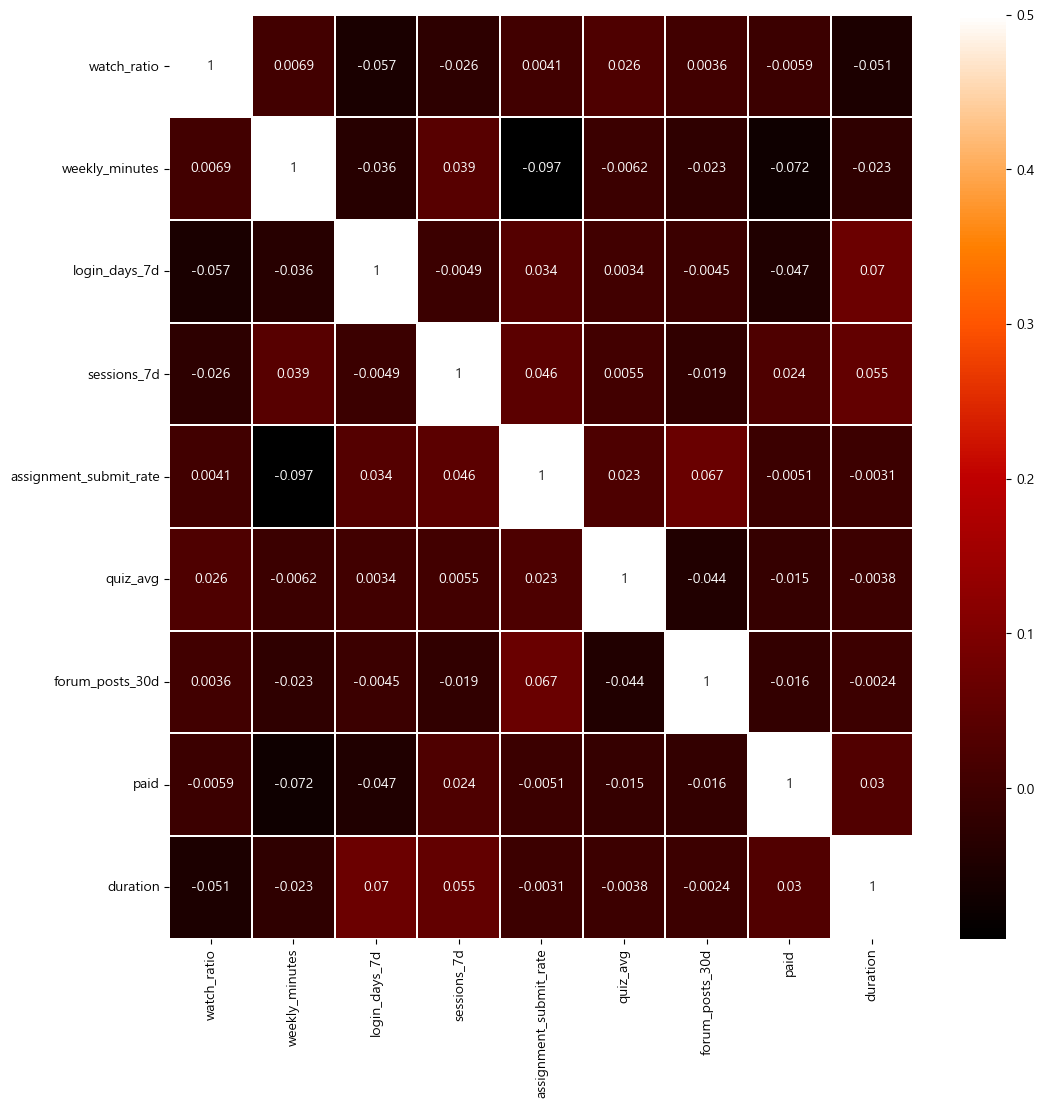

In [21]:
# 데이터 간의 상관 관계를 그래프로 표현해 봅니다.
colormap = plt.cm.gist_heat   #그래프의 색상 구성을 정합니다.
plt.figure(figsize=(12,12))   #그래프의 크기를 정합니다.

# 그래프의 속성을 결정합니다. vmax의 값을 0.5로 지정해 0.5에 가까울수록 밝은색으로 표시되게 합니다.
sns.heatmap(X.corr(),linewidths=0.1,vmax=0.5, cmap=colormap, linecolor='white', annot=True)
plt.show()

In [22]:
X

,watch_ratio,weekly_minutes,login_days_7d,sessions_7d,assignment_submit_rate,quiz_avg,forum_posts_30d,paid,duration
0,0.644,128.678281,3,7,0.061761,100.000000,0,0,18.0
1,0.418,155.622686,0,16,0.489122,51.141686,0,1,179.0
2,0.573,48.748187,5,15,0.173168,78.822025,1,1,57.0
3,0.445,230.454431,5,11,0.634181,97.648046,0,1,171.0
4,0.789,146.199604,5,11,0.109690,55.555740,0,0,48.0
...,...,...,...,...,...,...,...,...,...
995,0.265,162.421402,5,12,0.918949,57.540382,2,0,142.0
996,0.403,115.762365,0,14,0.564668,70.537085,2,1,153.0
997,0.237,159.548889,6,9,0.229696,67.150110,0,1,111.0
998,0.653,79.483340,5,8,0.465218,71.838697,3,1,56.0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
# 모델을 설정합니다.
model = Sequential()
model.add(Dense(12, input_dim=9, activation='relu', name='Dense_1'))
model.add(Dense(8, activation='relu', name='Dense_2'))
model.add(Dense(1, activation='sigmoid',name='Dense_3'))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Dense_1 (Dense)                 │ (None, 12)             │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_2 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 233 (932.00 B)

 Trainable params: 233 (932.00 B)

 Non-trainable params: 0 (0.00 B)

In [25]:
# 모델을 컴파일합니다.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 모델을 실행합니다.

history=model.fit(X_train, y_train, epochs=100, batch_size=5)

Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 895us/step - accuracy: 0.5192 - loss: 5.7960
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step - accuracy: 0.5743 - loss: 0.8479
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 954us/step - accuracy: 0.5710 - loss: 0.7258
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5609 - loss: 0.7365
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6060 - loss: 0.7170
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5893 - loss: 0.7142
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5710 - loss: 0.7105  
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 995us/step - accuracy: 0.5710 - loss: 0.7145
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 990us/step - accuracy: 0.5743 - loss: 0.6943
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5860 - loss: 0.7001
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 833us/step - accuracy: 0.5710 - loss: 0.7130
Epoch 12/100
120/120 ━━━━━━

In [26]:
#확실히 정확도가 높아졌으며 loss가 훨씬 감소하였음을 확인하였다.
y_pred_proba = model.predict(X_train)
y_pred = (y_pred_proba > 0.5).astype(int)

train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
훈련 Loss: [0.547362208366394, 0.7145242094993591]
테스트 Loss: [0.5901736617088318, 0.661478579044342]


In [27]:
# 모델을 설정합니다.
model = Sequential()
model.add(Dense(64, input_dim=9, activation='relu', name='Dense_1'))
model.add(Dense(32, activation='relu', name='Dense_2'))
model.add(Dense(16, activation='relu', name='Dense_3'))
model.add(Dense(1, activation='sigmoid',name='output'))
model.summary()
# 64 * 9 + 64 = 640
# 64 * 32 + 32 = 2080
# 32 * 16 + 32 = 528
# 16 * 1 + 1 = 17  

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Dense_1 (Dense)                 │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,265 (12.75 KB)

 Trainable params: 3,265 (12.75 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# 모델을 컴파일합니다.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 모델을 실행합니다.

history=model.fit(X_train, y_train, epochs=100, batch_size=5)

Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 844us/step - accuracy: 0.4841 - loss: 2.6291 
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 886us/step - accuracy: 0.5776 - loss: 0.7312
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 841us/step - accuracy: 0.6110 - loss: 0.7161
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 948us/step - accuracy: 0.5643 - loss: 0.7007
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 837us/step - accuracy: 0.6060 - loss: 0.7071
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 837us/step - accuracy: 0.5426 - loss: 0.7600
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 825us/step - accuracy: 0.5843 - loss: 0.6986
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 924us/step - accuracy: 0.5860 - loss: 0.6838
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 807us/step - accuracy: 0.5793 - loss: 0.6850
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 836us/step - accuracy: 0.5977 - loss: 0.6879
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step - accuracy: 0.5977 - loss: 0.6749
Epoch 12/100
120/1

In [29]:
train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

훈련 Loss: [0.45766112208366394, 0.7913188934326172]
테스트 Loss: [0.572716236114502, 0.7120622396469116]


In [30]:
# 모델을 컴파일합니다.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 모델을 실행합니다.

history=model.fit(X_train, y_train, epochs=100, batch_size=32)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7679 - loss: 0.4733   
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8047 - loss: 0.4515 
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7880 - loss: 0.4509 
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7796 - loss: 0.4474 
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7863 - loss: 0.4383 
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7830 - loss: 0.4547 
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7947 - loss: 0.4390 
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8030 - loss: 0.4238 
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8013 - loss: 0.4334 
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8013 - loss: 0.4221 
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8013 - loss: 0.4227 
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/ste

In [31]:
train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

훈련 Loss: [0.31744831800460815, 0.8514190316200256]
테스트 Loss: [0.6567398905754089, 0.7003890872001648]


In [32]:
# 모델을 컴파일합니다.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 모델을 실행합니다.

history=model.fit(X_train, y_train, epochs=100, batch_size=16)

Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8230 - loss: 0.3623   
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8364 - loss: 0.3373 
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8447 - loss: 0.3457 
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8130 - loss: 0.3541 
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8464 - loss: 0.3350 
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8414 - loss: 0.3412 
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8264 - loss: 0.3527 
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8297 - loss: 0.3467 
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8381 - loss: 0.3525 
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8364 - loss: 0.3343 
Epoch 11/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8481 - loss: 0.3255 
Epoch 12/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/ste

In [33]:
#확실히 정확도와 로스가 많이 떨어진것을 확인할 수 있었다.
y_pred_proba = model.predict(X_train)
y_pred = (y_pred_proba > 0.5).astype(int)

train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
훈련 Loss: [0.256745845079422, 0.8831385374069214]
테스트 Loss: [0.8214389085769653, 0.7042801380157471]


In [34]:
# 모델을 컴파일합니다.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 모델을 실행합니다.

history=model.fit(X_train, y_train, epochs=100, batch_size=8)

Epoch 1/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8548 - loss: 0.3369 
Epoch 2/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8681 - loss: 0.3050
Epoch 3/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8765 - loss: 0.2731
Epoch 4/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8564 - loss: 0.2846
Epoch 5/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8414 - loss: 0.2884
Epoch 6/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8230 - loss: 0.3508
Epoch 7/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8548 - loss: 0.3124
Epoch 8/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8564 - loss: 0.3044
Epoch 9/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8431 - loss: 0.3158
Epoch 10/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8531 - loss: 0.3138
Epoch 11/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8715 - loss: 0.2791
Epoch 12/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy

In [35]:
#확실히 정확도와 로스가 많이 떨어진것을 확인할 수 있었다.
train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

훈련 Loss: [0.20942048728466034, 0.904841423034668]
테스트 Loss: [0.8913975358009338, 0.6964980363845825]


In [ ]:
# 모델을 설정합니다.
model = Sequential()
model.add(Dense(64, input_dim=9, activation='relu', name='Dense_1'))
model.add(Dense(16, activation='relu', name='Dense_3'))
model.add(Dense(1, activation='sigmoid',name='output'))
model.summary()
# 64 * 9 + 64 = 640
# 64 * 32 + 32 = 2080
# 32 * 16 + 32 = 528
# 16 * 1 + 1 = 17  
#이렇게 은닉층 간의 간격을 64-> 16 처럼 훅훅 줄이게 되면 문제가 생긴다
#쉽게 발산하며 adam으로 돌리게 되면 심지어 음수값들도 다 날라가서 더 심각해진다.

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Dense_1 (Dense)                 │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_3 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,697 (6.63 KB)

 Trainable params: 1,697 (6.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 모델을 컴파일합니다.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 모델을 실행합니다.

history=model.fit(X_train, y_train, epochs=100, batch_size=8)

Epoch 1/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5409 - loss: 1.5728  
Epoch 2/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 983us/step - accuracy: 0.5509 - loss: 0.8790
Epoch 3/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5810 - loss: 0.8187
Epoch 4/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 872us/step - accuracy: 0.5659 - loss: 0.8996
Epoch 5/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 938us/step - accuracy: 0.5893 - loss: 0.8230
Epoch 6/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 821us/step - accuracy: 0.5910 - loss: 0.7766
Epoch 7/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 985us/step - accuracy: 0.5910 - loss: 0.8031
Epoch 8/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 793us/step - accuracy: 0.6093 - loss: 0.7302
Epoch 9/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 907us/step - accuracy: 0.6060 - loss: 0.7447
Epoch 10/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 927us/step - accuracy: 0.5960 - loss: 0.7842
Epoch 11/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6160 - loss: 0.7378  
Epoch 12/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [38]:
#확실히 정확도와 로스가 많이 떨어진것을 확인할 수 있었다.
train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

훈련 Loss: [0.4809665083885193, 0.7429048418998718]
테스트 Loss: [0.57701176404953, 0.7276264429092407]


In [39]:
# 모델을 컴파일합니다.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 모델을 실행합니다.

history=model.fit(X_train, y_train, epochs=200, batch_size=8)

Epoch 1/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7295 - loss: 0.5264  
Epoch 2/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7496 - loss: 0.4938
Epoch 3/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 944us/step - accuracy: 0.7462 - loss: 0.4971
Epoch 4/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 958us/step - accuracy: 0.7396 - loss: 0.5537
Epoch 5/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7429 - loss: 0.4962
Epoch 6/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 902us/step - accuracy: 0.7696 - loss: 0.4852
Epoch 7/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 950us/step - accuracy: 0.7663 - loss: 0.4993
Epoch 8/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7663 - loss: 0.4960  
Epoch 9/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 951us/step - accuracy: 0.7813 - loss: 0.4699
Epoch 10/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7629 - loss: 0.5213
Epoch 11/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 938us/step - accuracy: 0.7362 - loss: 0.5261
Epoch 12/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 964u

In [40]:
#확실히 정확도와 로스가 많이 떨어진것을 확인할 수 있었다.
train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

훈련 Loss: [0.31760460138320923, 0.8580968379974365]
테스트 Loss: [0.664890468120575, 0.7431906461715698]


In [ ]:
# 모델을 컴파일합니다.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 모델을 실행합니다.

history=model.fit(X_train, y_train, epochs=200, batch_size=3)

Epoch 1/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8798 - loss: 0.2940
Epoch 2/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 877us/step - accuracy: 0.8831 - loss: 0.2949
Epoch 3/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 943us/step - accuracy: 0.8664 - loss: 0.3775
Epoch 4/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8531 - loss: 0.3557
Epoch 5/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8715 - loss: 0.3050
Epoch 6/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8581 - loss: 0.3225
Epoch 7/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8598 - loss: 0.3108
Epoch 8/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8681 - loss: 0.3131
Epoch 9/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8314 - loss: 0.3605
Epoch 10/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8431 - loss: 0.3825
Epoch 11/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8531 - loss: 0.3133
Epoch 12/200
200/200 ━━━━━━━━━━━━━━━━

In [46]:
#확실히 정확도와 로스가 많이 떨어진것을 확인할 수 있었다.
train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

훈련 Loss: [0.1940653771162033, 0.9215359091758728]
테스트 Loss: [1.0973148345947266, 0.7042801380157471]


In [51]:
# 모델을 컴파일합니다.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 모델을 실행합니다.

history=model.fit(X_train, y_train, epochs=100, batch_size=32)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9683 - loss: 0.0978   
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9683 - loss: 0.0874 
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9750 - loss: 0.0890 
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9716 - loss: 0.0833 
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9666 - loss: 0.0866 
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9699 - loss: 0.0805 
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9666 - loss: 0.0887 
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9666 - loss: 0.0875 
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9699 - loss: 0.0921 
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9716 - loss: 0.0817 
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9699 - loss: 0.0875 
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/ste

In [52]:
#확실히 정확도와 로스가 많이 떨어진것을 확인할 수 있었다.
train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

훈련 Loss: [0.06695929169654846, 0.9749582409858704]
테스트 Loss: [1.6883087158203125, 0.7003890872001648]


In [57]:
# 모델을 컴파일합니다.
model.compile(loss='binary_crossentropy', optimizer='sgd', metrics=['accuracy'])

# 모델을 실행합니다.

history=model.fit(X_train, y_train, epochs=100, batch_size=8)

Epoch 1/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 852us/step - accuracy: 0.6010 - loss: 0.8022 
Epoch 2/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 890us/step - accuracy: 0.6427 - loss: 0.6809
Epoch 3/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 859us/step - accuracy: 0.6027 - loss: 0.7534
Epoch 4/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 918us/step - accuracy: 0.5960 - loss: 0.7306
Epoch 5/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 849us/step - accuracy: 0.6160 - loss: 0.6989
Epoch 6/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 934us/step - accuracy: 0.6244 - loss: 0.6815
Epoch 7/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 938us/step - accuracy: 0.5977 - loss: 0.9578
Epoch 8/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step - accuracy: 0.5910 - loss: 0.9834
Epoch 9/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 925us/step - accuracy: 0.5927 - loss: 0.9159
Epoch 10/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 992us/step - accuracy: 0.5826 - loss: 0.8009
Epoch 11/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 952us/step - accuracy: 0.5943 - loss: 0.7114
Epoch 12/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 

In [58]:
#확실히 정확도와 로스가 많이 떨어진것을 확인할 수 있었다.
train_loss = model.evaluate(X_train, y_train, verbose=0)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"훈련 Loss: {train_loss}")
print(f"테스트 Loss: {test_loss}")

훈련 Loss: [0.6049732565879822, 0.6761268973350525]
테스트 Loss: [0.6631413102149963, 0.5953307151794434]
